# Layer 4 in practice: power spectra

This notebook executes the material of {doc}`../layer4_spectra`: the spectra of
the named tracers from one halo field, the one-halo, two-halo and shot-noise
parts of the galaxy spectrum, the beyond-linear halo bias and the damping of the
one-halo plateau on the matter spectrum, and the baryonic suppression.
It runs on a `pip install` of `ggah_mod` plus `matplotlib`.
Layers 3 and 4 are work in progress, and the notice they emit on import is silenced below.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import warnings

import matplotlib.pyplot as plt
import numpy as np

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)

import ggah_mod.sectors as S
import ggah_mod.spectra as SP
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.field import make_field
from ggah_mod.halos.profiles import ejected_uk

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (6.4, 4.0),
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"ggah_mod {ggah_mod.__version__}, jax {jax.__version__}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod 1.7.0, jax 0.10.2


## One field, every tracer

The field is at $z = 0.25$; the galaxies are `zumandelbaum15` at their defaults,
the hot gas the DPM at its defaults, and the matter split is the one whose hot
gas is the profile's own, with the gas cut at $R_\Delta$ and the ejected gas on
its shell.

In [2]:
field = make_field(PLANCK18, DIFFERENTIABLE, make_pk("emu_pk"), z=0.25)
k = np.asarray(field.k)
gal, gp = S.GalaxySector("zumandelbaum15", calibration="off"), S.galaxy_defaults("zumandelbaum15")
gas, dp = S.HotGasDPM(backend=DIFFERENTIABLE), S.DpmParams()
f_cen, f_sat = gal.stellar_fraction(field, gp, satellites=True)
split = S.EjectaSector.split_from_gas(field, gas, dp, f_star_cen=f_cen, f_star_sat=f_sat)
u_gas = gas.bound_uk(field.k, field.m, field.z, field.cosmo, dp, field.mdef, conc=field.conc)
u_ej = ejected_uk(field.k, field.r_delta, eta_ej=2.0)

sectors = {"galaxies": gal, "gas": gas, "agn": S.AgnSector(gal, calibration="off"),
           "matter": S.MatterField(), "ejecta": S.EjectaSector()}
params = {"galaxies": gp, "gas": dp, "agn": S.AgnParams(),
          "matter": {"split": split, "u_gas": u_gas, "u_ej": u_ej}, "ejecta": {"split": split}}
options = SP.PkOptions.from_backend(DIFFERENTIABLE)

## Auto- and cross-spectra

*(a)* The auto-spectra of six tracers and *(b)* their cross-spectra with the
galaxies, each divided by the tracer's two-halo amplitude relative to the
matter's at the smallest $k$ (squared for an auto-spectrum), so that the curves
coincide on large scales and differ only in shape.

each spectrum is divided by its tracer's two-halo amplitude relative to the matter at k_min


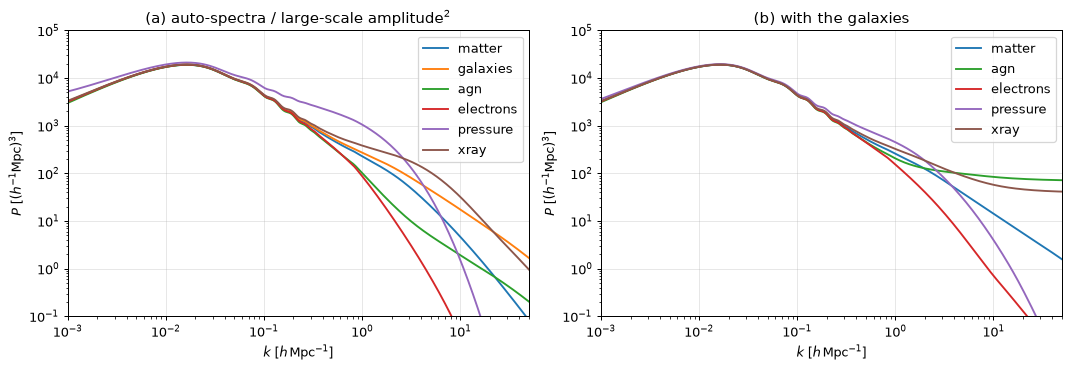

In [3]:
names = ("matter", "galaxies", "agn", "electrons", "pressure", "xray")

def contrast_norm(name):
    # The two-halo amplitude at k -> 0 over that of the matter: the tracer's mean
    # times its large-scale bias, divided out so the curves share one unit.
    p = SP.spectrum(field, name, "matter", sectors, params, options=options)
    m = SP.spectrum(field, "matter", "matter", sectors, params, options=options)
    return float(p.two_halo[0] / m.two_halo[0])

norm = {n: contrast_norm(n) for n in names}
fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.2))
for i, n in enumerate(names):
    auto = SP.spectrum(field, n, n, sectors, params, options=options)
    ax[0].loglog(k, np.asarray(auto.total) / norm[n] ** 2, f"C{i}", label=n)
    if n != "galaxies":
        cross = SP.spectrum(field, "galaxies", n, sectors, params, options=options)
        ax[1].loglog(k, np.abs(np.asarray(cross.total)) / (norm[n] * norm["galaxies"]), f"C{i}", label=n)
for a, t in zip(ax, ("(a) auto-spectra / large-scale amplitude$^2$", "(b) with the galaxies")):
    a.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$P\ [(h^{-1}{\rm Mpc})^3]$",
          xlim=(1e-3, 50), ylim=(1e-1, 1e5), title=t)
    a.legend()
fig.tight_layout()
print("each spectrum is divided by its tracer's two-halo amplitude relative to the matter at k_min")

## The parts of the galaxy spectrum

$P_{\rm gg}$ (black) with its one-halo (dashed) and two-halo (dotted) terms and
its shot noise $1/\bar n$ (grey), which is kept apart from the total.

n = 4.978e-03 h^3 Mpc^-3, shot noise 200.9


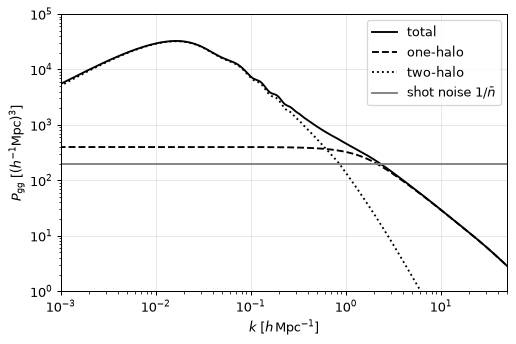

In [4]:
p_gg = SP.spectrum(field, "galaxies", "galaxies", sectors, params, options=options)
fig, ax = plt.subplots()
ax.loglog(k, p_gg.total, "k", label="total")
ax.loglog(k, p_gg.one_halo, "k--", label="one-halo")
ax.loglog(k, p_gg.two_halo, "k:", label="two-halo")
ax.axhline(float(p_gg.shot), color="0.5", label=r"shot noise $1/\bar n$")
ax.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$P_{\rm gg}\ [(h^{-1}{\rm Mpc})^3]$",
       xlim=(1e-3, 50), ylim=(1, 1e5))
ax.legend()
print(f"n = {float(gal.number_density(field, gp)):.3e} h^3 Mpc^-3, shot noise {float(p_gg.shot):.1f}")

## Options on the matter spectrum

$P_{\rm mm}$ over the linear $P_{\rm m}$ with the default options (beyond-linear
bias on, no damping), without the beyond-linear bias, and with the `mead20`
damping of the one-halo plateau.

default   P/P_lin at k = 0.01, 0.5: [1.01191732 2.14021305]
bnl=False P/P_lin at k = 0.01, 0.5: [1.01191732 1.72693258]
mead20    P/P_lin at k = 0.01, 0.5: [0.99998209 2.13971682]


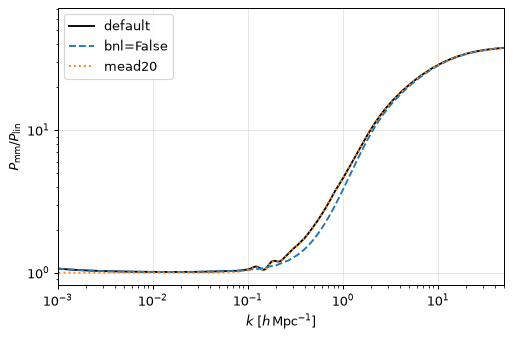

In [5]:
from ggah_mod.cosmology import make_pk as _mk
p_lin = np.asarray(field.pk_lin)
fig, ax = plt.subplots()
for label, opts, ls in (("default", options, "k"),
                        ("bnl=False", SP.PkOptions.from_backend(DIFFERENTIABLE, bnl=False), "C0--"),
                        ("mead20", SP.PkOptions.from_backend(DIFFERENTIABLE, one_halo_transition="mead20"), "C1:")):
    p = SP.spectrum(field, "matter", "matter", sectors, params, options=opts)
    ax.semilogx(k, np.asarray(p.total) / p_lin, ls, label=label)
    print(f"{label:9s} P/P_lin at k = 0.01, 0.5: {np.interp([0.01, 0.5], k, np.asarray(p.total) / p_lin)}")
ax.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$P_{\rm mm}/P_{\rm lin}$", xlim=(1e-3, 50), yscale="log")
ax.legend()

## Baryonic suppression

$S(k) = P_{\rm mm}/P_{\rm mm}^{\rm DMO}$ with the gas cut at $R_\Delta$ and the
ejected gas on shells of three radii.

eta_ej = 1.0: S at k = 1, 10: [0.94964705 0.77168821]
eta_ej = 2.0: S at k = 1, 10: [0.91325008 0.76719595]


eta_ej = 4.0: S at k = 1, 10: [0.89526534 0.76548314]


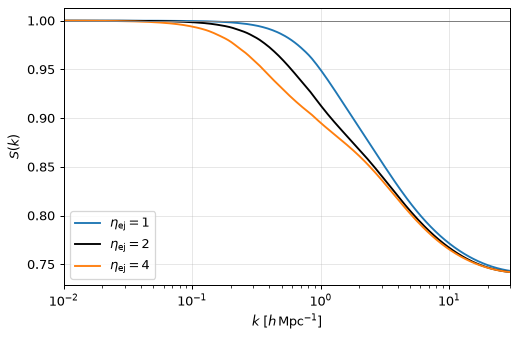

In [6]:
fig, ax = plt.subplots()
for eta, c in ((1.0, "C0"), (2.0, "k"), (4.0, "C1")):
    pm = dict(params, matter={"split": split, "u_gas": u_gas,
                              "u_ej": ejected_uk(field.k, field.r_delta, eta_ej=eta)})
    k_s, s_k = SP.matter_suppression(field, sectors, pm, options=options)
    ax.semilogx(k_s, s_k, c, label=rf"$\eta_{{\rm ej}} = {eta:g}$")
    print(f"eta_ej = {eta}: S at k = 1, 10: {np.interp([1.0, 10.0], k_s, s_k)}")
ax.axhline(1.0, color="0.5", lw=0.8)
ax.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel="$S(k)$", xlim=(1e-2, 30))
ax.legend()

## Things to try

- Cross `centrals` with `satellites`, then try `galaxies` with `centrals` and
  read the refusal of a nested pair.
- Build the AGN sector with `f_duty_sat=0` in `AgnParams` and look at the
  one-halo term of its auto-spectrum.
- Apply `ggah_mod.sectors.png.apply_png_bias` to the galaxy weights and follow
  $P_{\rm gg}$ at $k < 0.01\,h\,{\rm Mpc}^{-1}$.
- Drop the profiles from `params["matter"]` and check that $S(k) = 1$.

Previous: {doc}`layer3_hot_gas`. Next: {doc}`layer5_observables`.